# Лабораторная работа №2. Сверточная сеть на PyTorch

**Студент:** Ермолаев Д.А.  
**Группа:** 3825М1ФИ2

## Цель

Обучить сверточную сеть классификации CIFAR-10. Сеть описываем своим классом из свёрток $3 \times 3$, ReLU, max pooling и полносвязного слоя.


## Свёртка

Полносвязный слой заводит отдельный вес на каждый пиксель. Один и тот же край в разных местах изображения тогда требует разных весов.

Свёртка двигает одно ядро по всему полю. В библиотеках считается кросс-корреляция, её и называют свёрткой:

$$
s(i, j) = \sum_{m, n} I(i + m,\ j + n)\, K(m, n).
$$

Выход одного ядра — карта признаков. Несколько ядер дают несколько каналов: каждое ищет свой локальный шаблон. Края дополняем нулями, чтобы размер карты не уменьшался на каждой свёртке.

Слой собираем из трёх шагов:

1. свёртка;
2. ReLU;
3. max pooling $2 \times 2$ с шагом 2.

Вместо сигмоиды ставим ReLU: на положительной полуоси её производная равна 1, градиент не затухает. Pooling заменяет окрестность максимумом, поэтому небольшой сдвиг объекта почти не меняет выход, а следующая карта вдвое меньше.

Ядро $5 \times 5$ заменяем двумя ядрами $3 \times 3$. Рецептивное поле то же, весов меньше: $2 \cdot 3 \cdot 3 = 18$ против $25$ на один входной канал, и между свёртками стоит ReLU.

После свёрточных блоков разворачиваем карту в вектор и подаю в полносвязный слой. На выходе 10 логитов, по числу классов. `CrossEntropyLoss` уже считает log-softmax, поэтому softmax в сеть не ставим.


## Данные

В CIFAR-10 50 000 обучающих и 10 000 тестовых цветных изображений $32 \times 32$, 10 классов. Из каждого канала вычитаем среднее и делим на стандартное отклонение, посчитанные по обучающей выборке.

На обучении ещё случайно сдвигаем картинку и отражаем её по горизонтали: класс от этого не меняется. На тесте и при подсчёте ошибки обучения аугментации нет.


In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

CIFAR10_CLASSES = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

# Статистика каналов обучающей части CIFAR-10.
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_set = datasets.CIFAR10(root="data", train=True, download=True, transform=train_transform)
test_set = datasets.CIFAR10(root="data", train=False, download=True, transform=eval_transform)
# Отдельная копия без аугментации — чтобы смотреть картинки и считать ошибку на обучении.
train_view = datasets.CIFAR10(root="data", train=True, download=True, transform=eval_transform)

image, label = train_view[0]
print("обучающих примеров:", len(train_set))
print("тестовых примеров:", len(test_set))
print("одно изображение:", tuple(image.shape), image.dtype)
print("метка:", int(label), CIFAR10_CLASSES[label])


обучающих примеров: 50000
тестовых примеров: 10000
одно изображение: (3, 32, 32) torch.float32
метка: 6 frog


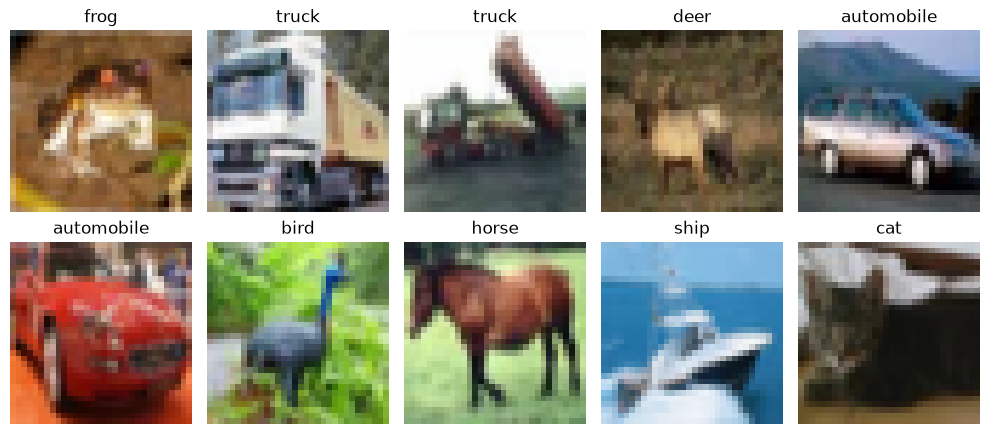

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, idx in zip(axes.ravel(), range(10)):
    # train_view хранит уже нормированный тензор. Для рисунка возвращаем масштаб.
    tensor, label = train_view[idx]
    picture = tensor.permute(1, 2, 0).numpy()
    picture = picture * CIFAR10_STD + CIFAR10_MEAN
    picture = picture.clip(0, 1)
    ax.imshow(picture)
    ax.set_title(CIFAR10_CLASSES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()


## Архитектура

Три блока. В каждом одна или две свёртки $3 \times 3$ с дополнением нулями, ReLU и max pooling $2 \times 2$. Каналов становится больше, $3 \to 32 \to 64 \to 128$, а сторона карты падает $32 \to 16 \to 8 \to 4$.

Дальше вектор $128 \cdot 4 \cdot 4$, полносвязный слой на 256 нейронов, ReLU, dropout и линейный слой на 10 логитов. Dropout на обучении обнуляет часть выходов, чтобы классификатор не опирался на один нейрон. На тесте он выключен.


In [3]:
class SmallVGG(nn.Module):
    def __init__(self, num_classes=10, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SmallVGG().to(device)
n_params = sum(p.numel() for p in model.parameters())
print("устройство:", device)
print("параметров:", n_params)

# Проверка размерностей на одной пачке.
with torch.no_grad():
    sample = torch.zeros(8, 3, 32, 32, device=device)
    logits = model(sample)
print("логиты пачки:", tuple(logits.shape))


устройство: cpu
параметров: 666538
логиты пачки: (8, 10)


## Обучение

Функция потерь — кросс-энтропия. Шаг делаем стохастическим градиентным спуском с импульсом: новое изменение весов — это $0.9$ от предыдущего изменения минус $\eta \nabla E$, $\eta = 0.01$. Пачка — 128 изображений, эпох — 15.

После каждой эпохи считаем кросс-энтропию, долю ошибок и точность на обучающей выборке без случайных сдвигов. Иначе число прыгало бы из-за аугментации, а не из-за весов.


In [4]:
BATCH_SIZE = 128
LEARNING_RATE = 0.01
MOMENTUM = 0.9
EPOCHS = 15

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
train_eval_loader = DataLoader(train_view, batch_size=256, shuffle=False)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)


def evaluate(loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            logits = model(inputs)
            loss = criterion(logits, targets)
            loss_sum += loss.item() * inputs.size(0)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += inputs.size(0)
    return loss_sum / total, 1.0 - correct / total, correct / total


history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    started = time.perf_counter()
    running_loss = 0.0
    seen = 0
    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        seen += inputs.size(0)

    train_loss, train_error, train_acc = evaluate(train_eval_loader)
    elapsed = time.perf_counter() - started
    history.append({
        "loss": train_loss,
        "error": train_error,
        "accuracy": train_acc,
        "batch_loss": running_loss / seen,
        "time": elapsed,
    })
    print(
        f"эпоха {epoch:02d}  "
        f"кросс-энтропия {train_loss:.4f}  "
        f"ошибка классификации {train_error:.4f}  "
        f"точность {train_acc:.4f}  "
        f"время {elapsed:.1f} с"
    )


эпоха 01  кросс-энтропия 1.8100  ошибка классификации 0.6569  точность 0.3431  время 54.0 с


эпоха 02  кросс-энтропия 1.5080  ошибка классификации 0.5491  точность 0.4509  время 53.5 с


эпоха 03  кросс-энтропия 1.3340  ошибка классификации 0.4874  точность 0.5126  время 52.6 с


эпоха 04  кросс-энтропия 1.1659  ошибка классификации 0.4109  точность 0.5891  время 53.9 с


эпоха 05  кросс-энтропия 0.9817  ошибка классификации 0.3479  точность 0.6521  время 52.8 с


...

эпоха 11  кросс-энтропия 0.5919  ошибка классификации 0.2064  точность 0.7936  время 54.0 с


эпоха 12  кросс-энтропия 0.5445  ошибка классификации 0.1883  точность 0.8117  время 53.3 с


эпоха 13  кросс-энтропия 0.5421  ошибка классификации 0.1891  точность 0.8109  время 53.0 с


эпоха 14  кросс-энтропия 0.5264  ошибка классификации 0.1829  точность 0.8171  время 54.9 с


эпоха 15  кросс-энтропия 0.5080  ошибка классификации 0.1760  точность 0.8240  время 54.7 с


тест: кросс-энтропия 0.5956
тест: ошибка классификации 0.2020
тест: точность 0.7980


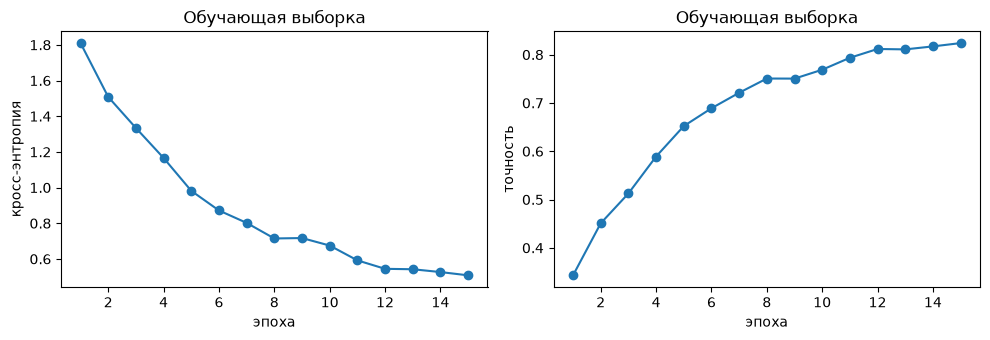

In [5]:
test_loss, test_error, test_acc = evaluate(test_loader)
print(f"тест: кросс-энтропия {test_loss:.4f}")
print(f"тест: ошибка классификации {test_error:.4f}")
print(f"тест: точность {test_acc:.4f}")

epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(epochs, [item["loss"] for item in history], marker="o")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("кросс-энтропия")
axes[0].set_title("Обучающая выборка")
axes[1].plot(epochs, [item["accuracy"] for item in history], marker="o")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("точность")
axes[1].set_title("Обучающая выборка")
plt.tight_layout()
plt.show()


## Ответы на тесте

Подписи — истинный класс и класс, который выбрала сеть.


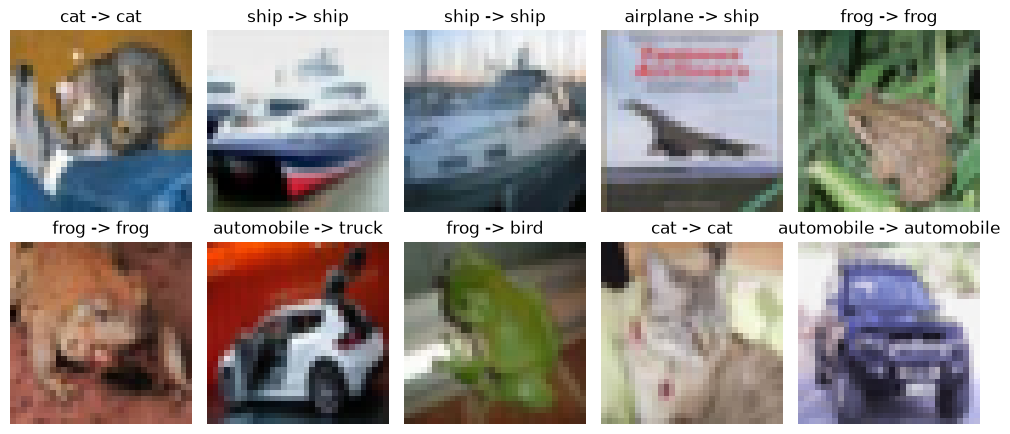

In [6]:
model.eval()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
with torch.no_grad():
    for ax, idx in zip(axes.ravel(), range(10)):
        tensor, label = test_set[idx]
        logits = model(tensor.unsqueeze(0).to(device))
        pred = int(logits.argmax(dim=1).item())
        picture = tensor.permute(1, 2, 0).numpy() * CIFAR10_STD + CIFAR10_MEAN
        ax.imshow(picture.clip(0, 1))
        ax.set_title(f"{CIFAR10_CLASSES[label]} -> {CIFAR10_CLASSES[pred]}")
        ax.axis("off")
plt.tight_layout()
plt.show()
